# 06 — Пересечение цены с быстрой MA + наклон медленной MA (5m, фьючерсы MOEX)

Ноутбук-просмотрщик масштабного исследования: ~9 млн конфигураций на инструмент (все 36 пар типов
средних, Fast 2–99 × Slow 5–250, два метода наклона, две модели выхода, подбор параметров наклона) на
NG, BR, WTI, GOLD, SILV, COPPER, PLT, PLD. Полный текстовый отчёт —
[`research/ma_cross_slope_5m/README.md`](../research/ma_cross_slope_5m/README.md).

Всё читается из файлов репозитория, пересчёт сеток не нужен:

* `research/ma_cross_slope_5m/tables/` — сводные таблицы, рейтинг, финалисты, walk-forward, PBO, межрыночная
  проверка;
* `research/ma_cross_slope_5m/grid/` — **все конфигурации** полных сеток (этапы 1 и 3) и решётки подбора
  наклона (этап 2) с метриками IS/OOS;
* `research/ma_cross_slope_5m/figures/` — рисунки отчёта;
* `data/raw/moex_algopack/` — свечи для пересчёта любой конфигурации через VectorBT (раздел 9).

Термины: **IS** — первые 70 % баров инструмента, **OOS** — последние 30 %; **t** — t-статистика средней
сделки; **плато** — средний IS t по соседним периодам (Fast ±2, Slow ±5); выход **reverse_cross** —
обратное пересечение Fast MA, **slope_flip** — смена наклона Slow MA на противоположный; метод наклона
**pct** — изменение MA в %, **atr** — в единицах ATR.

In [1]:
import json
import tempfile
import warnings
from io import BytesIO
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from src.ma_slope import analysis as A
from src.ma_slope import finalist as F
from src.ma_slope import plots as P
from src.ma_slope.averages import MA_TYPES
from src.ma_slope.data import TICK_SIZES, TICKERS, load_instrument
from src.ma_slope.grid import EXIT_MODELS, Slope
from src.utils.paths import PROJECT_ROOT

STUDY = PROJECT_ROOT / "research" / "ma_cross_slope_5m"
TABLES, FIGS, GRID = STUDY / "tables", STUDY / "figures", STUDY / "grid"
INF = ["ng", "br", "gold", "silv", "plt", "pld", "copper"]  # WTI: 2 181 bars, descriptive only
NAMES = {"ng": "NG", "br": "BR (Brent)", "wti": "WTI (CL)", "gold": "GOLD (GC)", "silv": "SILV (SI)",
         "copper": "COPPER (HG)", "plt": "PLT (PL)", "pld": "PLD (PA)"}
TMP = Path(tempfile.mkdtemp())

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:.3f}".format)


def show(name, width=1300, folder=FIGS):
    """Display a figure, downscaled to a 256-colour palette so the executed notebook stays light."""
    img = PILImage.open(Path(folder) / name).convert("RGB")
    if img.width > width:
        img = img.resize((width, round(img.height * width / img.width)), PILImage.LANCZOS)
    buf = BytesIO()
    img.quantize(colors=256, method=PILImage.Quantize.MEDIANCUT).save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue()))


def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


def grid_meta(stage, ticker):
    return json.loads(pq.read_schema(GRID / f"{stage}_{ticker}.parquet").metadata[b"ma_slope"])


def load_full_grid(ticker, stage="stage3"):
    """All 3 471 552 configs of one instrument's full grid with IS/OOS metrics."""
    return pd.read_parquet(GRID / f"{stage}_{ticker}.parquet")


summary = json.loads((TABLES / "summary.json").read_text())
print("Файлы сеток:", sorted(p.name for p in GRID.glob("*.parquet")))

Файлы сеток: ['stage1_br.parquet', 'stage1_copper.parquet', 'stage1_gold.parquet', 'stage1_ng.parquet', 'stage1_pld.parquet', 'stage1_plt.parquet', 'stage1_silv.parquet', 'stage1_wti.parquet', 'stage2_br.parquet', 'stage2_copper.parquet', 'stage2_gold.parquet', 'stage2_ng.parquet', 'stage2_pld.parquet', 'stage2_plt.parquet', 'stage2_silv.parquet', 'stage2_wti.parquet', 'stage3_br.parquet', 'stage3_copper.parquet', 'stage3_gold.parquet', 'stage3_ng.parquet', 'stage3_pld.parquet', 'stage3_plt.parquet', 'stage3_silv.parquet', 'stage3_wti.parquet']


## 1. Главное

* **Устойчивого торгового преимущества у конкретных параметров не найдено.** Ни одна конфигурация не проходит
  поправку на множественное тестирование; лучшие по IS на независимой выборке в среднем не лучше случайной
  конфигурации из той же сетки (кроме PLT и PLD).
* **Результат определяет режим рынка.** Одни и те же правила зарабатывают или теряют почти всей сеткой сразу
  (золото и серебро: минус на IS, плюс на OOS; PLT и PLD — наоборот).
* **Выход по смене наклона (slope_flip) лучше обратного пересечения** на IS на всех 7 рынках и на OOS на 6 из 7.
* **Горизонт наклона k = 40–80 баров (3–7 часов)** — главный параметр фильтра; ширина нейтральной зоны и метод
  (pct/atr) почти не важны.
* **Типы средних — эффект второго порядка**: медленная EMA/SSMA/WMA немного лучше SMA/TMA/VWMA.
* **Walk-forward с ежегодным переотбором** даёт плюс на всех 6 рынках с длинной историей (значимо на NG и PLT после
  поправки Холма), но заметная часть — общий трендовый дрейф; средняя OOS-сделка на NG, BR, SILV — 0,5–1,8 тика.

Цифры ниже — из таблиц исследования.

## 2. Данные

In [2]:
rows = []
for t in TICKERS:
    m = grid_meta("stage3", t)
    rows.append({"инструмент": NAMES[t], "5m баров": m["bars"], "начало": m["start"][:10], "конец": m["end"][:10],
                 "граница IS/OOS": m["split_time"][:10], "USD за 1 пункт": m["multiplier"], "тик": TICK_SIZES[t]})
pd.DataFrame(rows)

,инструмент,5m баров,начало,конец,граница IS/OOS,USD за 1 пункт,тик
0,NG,282539,2020-02-03,2026-10-13,2025-02-07,100.000,0.001
1,BR (Brent),607705,2011-12-19,2026-10-13,2022-11-03,10.000,0.010
2,WTI (CL),2181,2026-07-14,2026-10-13,2026-09-28,10.000,0.010
3,GOLD (GC),614498,2011-12-19,2026-10-13,2022-10-24,1.000,0.100
4,SILV (SI),564537,2011-12-19,2026-10-13,2023-02-27,10.000,0.010
5,PLT (PL),331877,2011-12-19,2026-10-13,2024-07-17,1.000,0.100
6,PLD (PA),237104,2011-12-19,2026-10-13,2025-04-25,1.000,0.010
7,COPPER (HG),62325,2024-10-08,2026-10-13,2026-05-29,0.010,1.000


In [3]:
print("Конфигураций на инструмент (этапы 1 + 2 + 3):", summary["trials_per_instrument"])
print("Ожидаемый максимум t среди стольких нулевых тестов:",
      {t: round(v, 2) for t, v in summary["expected_max_t_null"].items()})

Конфигураций на инструмент (этапы 1 + 2 + 3): {'ng': 8979840, 'br': 8979840, 'wti': 2387269, 'gold': 8979840, 'silv': 8979840, 'plt': 8979840, 'pld': 8979840, 'copper': 7495793}
Ожидаемый максимум t среди стольких нулевых тестов: {'ng': 5.29, 'br': 5.29, 'wti': 5.04, 'gold': 5.29, 'silv': 5.29, 'plt': 5.29, 'pld': 5.29, 'copper': 5.25}


## 3. Методология в двух абзацах

Сигнал — пересечение Close и Fast MA по двум закрытым свечам, исполнение по Open следующей свечи; long при наклоне
Slow MA вверх или нейтрально, short — вниз или нейтрально; 1 контракт, без издержек, без разворота на свече выхода.
Наклон за k баров: `pct` — `(MA[t]−MA[t−k])/MA[t−k]·100`, `atr` — `(MA[t]−MA[t−k])/ATR[t]`, нейтрально при
|наклон| ≤ ε. Формулы шести средних (SMA, EMA, WMA, SSMA, VWMA, TMA) и способы инициализации — в отчёте, раздел 3.1.

Этап 1 — полная сетка (3 471 552 конфигурации) при заранее заданном наклоне (k = 10, ε = 0,02 % / 0,25·ATR14);
этап 2 — 128 настроек наклона на логарифмической решётке периодов; этап 3 — снова полная сетка с выбранным на IS
наклоном. Отбор — по плато IS t (не по прибыли), проверка — OOS, walk-forward, PBO, Monte Carlo, поправки Холма и
Benjamini–Hochberg, межрыночная проверка. PnL — в USD на контракт по изменению сырой цены удерживаемого контракта,
ролл — по цене перекрытия.

## 4. Вся сетка: режим рынка важнее параметров

In [4]:
s = table("grid_summary.csv")
s = s[(s["stage"] == "stage3") & s["ticker"].isin(INF)]


def weighted(g, col):
    return (g[col] * g["configs"]).sum() / g["configs"].sum()


rows = []
for (t, model), g in s.groupby(["ticker", "model"]):
    rows.append({"инструмент": NAMES[t], "выход": model, "IS t медиана": weighted(g, "is_t_median"),
                 "IS доля t>0": weighted(g, "is_share_pos"), "OOS t медиана": weighted(g, "oos_t_median"),
                 "OOS доля t>0": weighted(g, "oos_share_pos"), "ρ(IS,OOS)": weighted(g, "spearman_is_oos")})
pd.DataFrame(rows).sort_values(["инструмент", "выход"]).reset_index(drop=True)

,инструмент,выход,IS t медиана,IS доля t>0,OOS t медиана,OOS доля t>0,"ρ(IS,OOS)"
0,BR (Brent),reverse_cross,1.105,0.822,-0.397,0.273,0.285
1,BR (Brent),slope_flip,2.121,0.987,0.767,0.879,0.104
2,COPPER (HG),reverse_cross,-2.848,0.000,-1.557,0.007,-0.039
3,COPPER (HG),slope_flip,-0.766,0.188,0.154,0.583,0.148
4,GOLD (GC),reverse_cross,-1.528,0.023,0.742,0.776,0.469
5,GOLD (GC),slope_flip,0.466,0.793,1.959,0.996,-0.098
6,NG,reverse_cross,1.056,0.784,0.868,0.836,0.313
7,NG,slope_flip,1.588,0.975,0.575,0.794,-0.181
8,PLD (PA),reverse_cross,1.343,0.951,-0.278,0.369,0.367
9,PLD (PA),slope_flip,1.997,0.982,-0.025,0.499,0.693


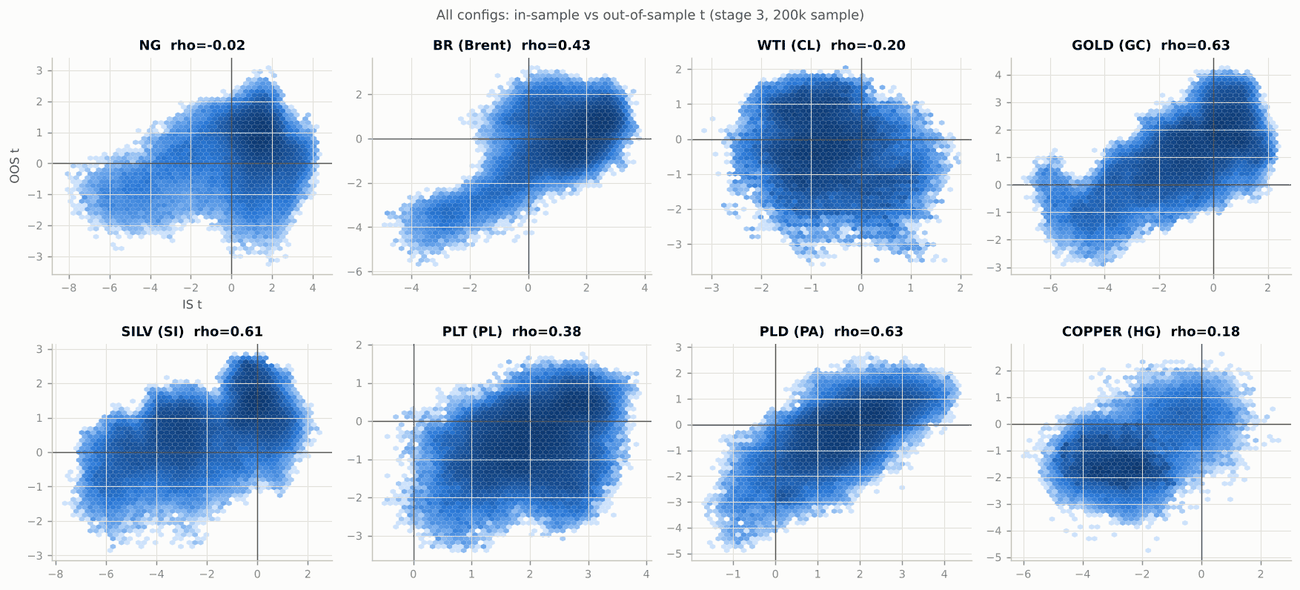

In [5]:
show("is_vs_oos.png")

## 5. Сравнение 36 сочетаний типов средних

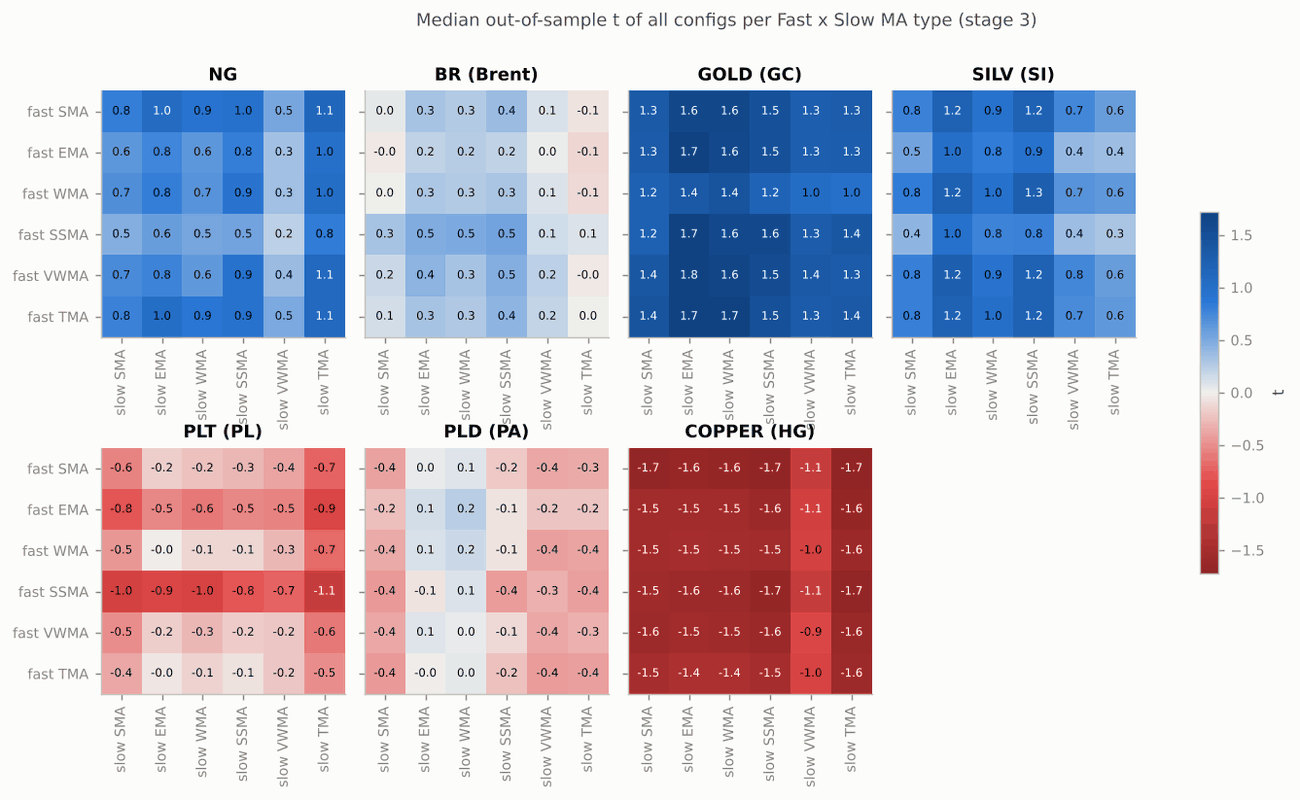

In [6]:
show("type_pairs_oos_median_t.png")

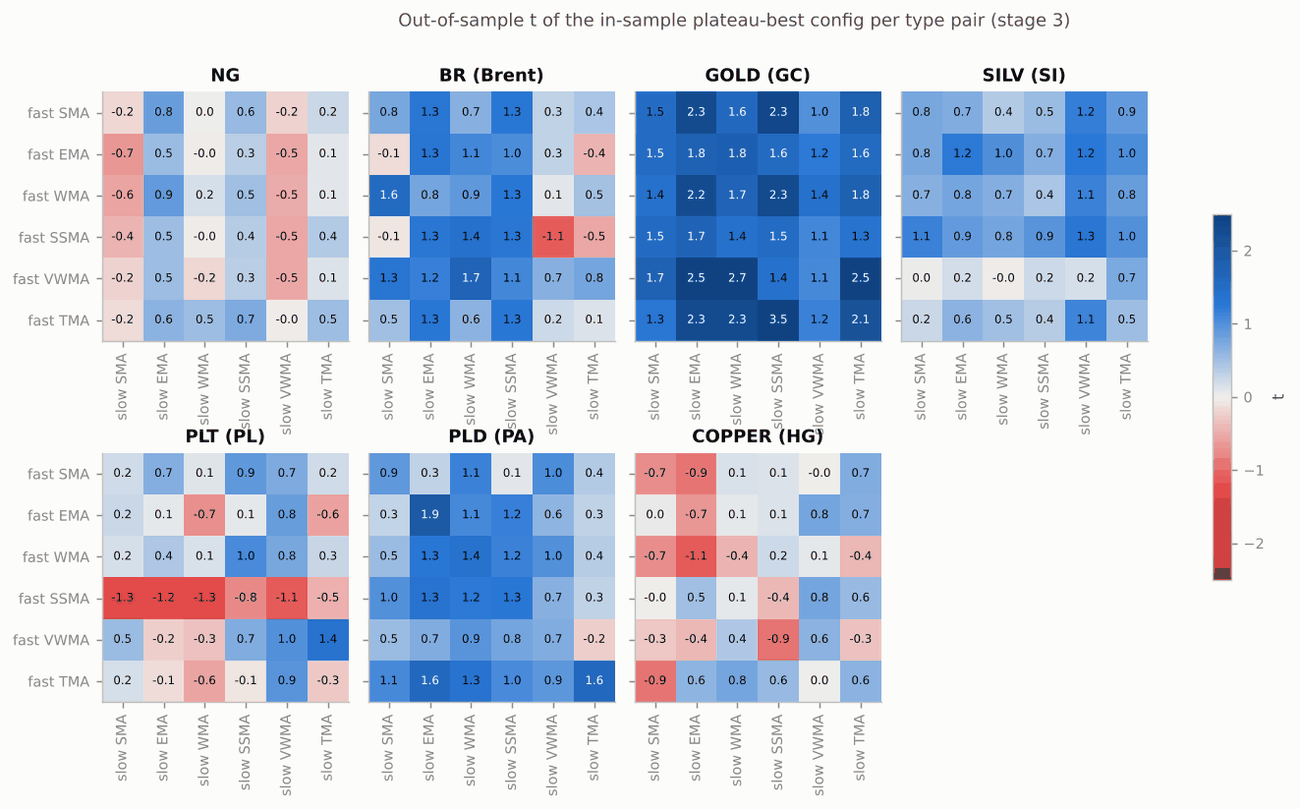

In [7]:
show("type_pairs_best_oos_t.png")

In [8]:
tp = table("type_pairs.csv")
tp = tp[(tp["stage"] == "stage3") & tp["ticker"].isin(INF)]
pairs = (tp.groupby(["fast_type", "slow_type"])
           .agg(OOS_t_медиана=("oos_t_median", "mean"), IS_t_медиана=("is_t_median", "mean"),
                OOS_t_лучшей_по_IS=("best_oos_t", "mean"), рынков_с_плюсом=("best_oos_t", lambda x: int((x > 0).sum())))
           .sort_values("OOS_t_медиана", ascending=False))
display(Markdown("**Средние по 7 рынкам, лучшие и худшие сочетания (fast → slow):**"))
pd.concat([pairs.head(8), pairs.tail(5)])

**Средние по 7 рынкам, лучшие и худшие сочетания (fast → slow):**

OOS_t_медиана  IS_t_медиана  OOS_t_лучшей_по_IS  рынков_с_плюсом
fast_type slow_type                                                                  
TMA       EMA                0.397         0.520               0.987                6
VWMA      EMA                0.375         0.490               0.623                5
SMA       EMA                0.344         0.460               0.740                6
TMA       WMA                0.332         0.511               0.784                6
WMA       EMA                0.326         0.437               0.751                6
VWMA      SSMA               0.324         0.406               0.517                6
TMA       SSMA               0.321         0.416               1.049                6
WMA       SSMA               0.278         0.322               0.984                7
          TMA               -0.021         0.013               0.478                6
SSMA      VWMA              -0.026         0.369               0.151                4
EMA       TMA               -0.047         0.090               0.375                5
SSMA      SMA               -0.082         0.249               0.252                3
          TMA               -0.088         0.103               0.368                5

In [9]:
display(pd.DataFrame({"быстрая (главный эффект)": tp.groupby("fast_type")["oos_t_median"].mean(),
                      "медленная (главный эффект)": tp.groupby("slow_type")["oos_t_median"].mean()}).loc[list(MA_TYPES)])

,быстрая (главный эффект),медленная (главный эффект)
SMA,0.176,0.036
EMA,0.098,0.310
WMA,0.160,0.241
SSMA,0.031,0.241
VWMA,0.211,0.082
TMA,0.236,0.002


## 6. Модели выхода

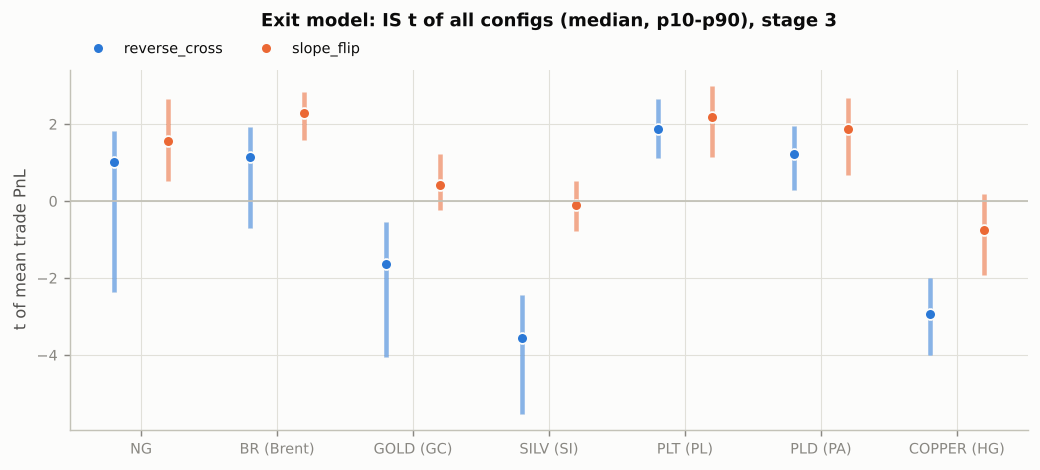

In [10]:
show("exit_models_is.png")

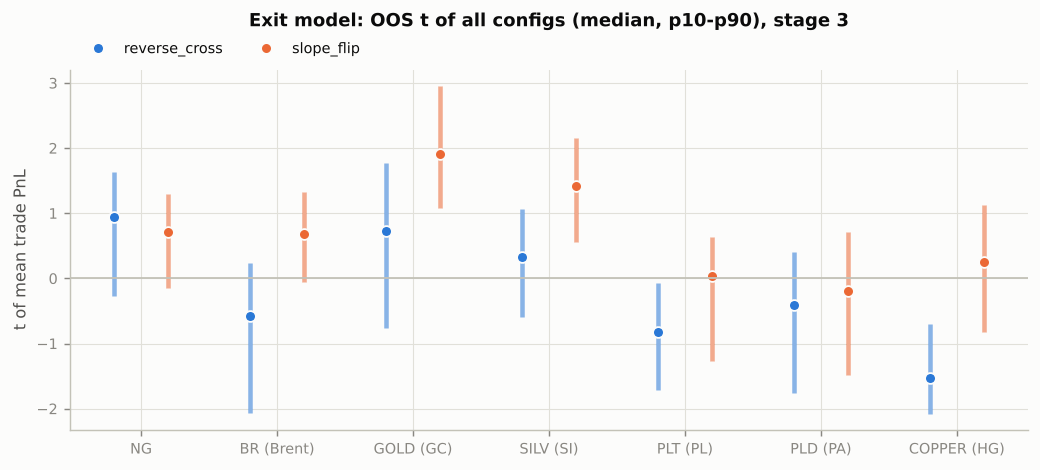

In [11]:
show("exit_models_oos.png")

## 7. Методы определения наклона и подбор параметров

In [12]:
rows = []
for (t, method), g in s.groupby(["ticker", "method"]):
    rows.append({"инструмент": NAMES[t], "метод": method, "OOS t медиана": weighted(g, "oos_t_median"),
                 "OOS доля t>0": weighted(g, "oos_share_pos")})
pd.DataFrame(rows).pivot(index="инструмент", columns="метод")

OOS t медиана        OOS доля t>0      
метод                 atr    pct          atr   pct
инструмент                                         
BR (Brent)          0.062  0.309        0.528 0.624
COPPER (HG)        -1.381 -1.274        0.071 0.097
GOLD (GC)           1.358  1.344        0.884 0.887
NG                  0.734  0.709        0.819 0.811
PLD (PA)           -0.153 -0.151        0.434 0.433
PLT (PL)           -0.388 -0.328        0.289 0.315
SILV (SI)           0.813  0.841        0.816 0.822

In [13]:
sw = table("slope_sweep.csv")
sw = sw[sw["ticker"].isin(INF)]
display(Markdown("**Медианный IS t по всем рынкам и решётке: горизонт k против порога ε (метод pct)**"))
display(sw.groupby("k")["is_median_t"].mean().to_frame("IS t медиана").T)
display(sw[sw["method"] == "pct"].groupby("eps")["is_median_t"].mean().to_frame("IS t медиана").T)
chosen = []
for (t, method, model), g in sw.groupby(["ticker", "method", "model"]):
    b = g.loc[g["is_median_t"].idxmax()]
    base = g[(g["k"] == 10) & ((g["eps"] == 0.02) if method == "pct" else ((g["eps"] == 0.25) & (g["atr_n"] == 14)))].iloc[0]
    chosen.append({"инструмент": NAMES[t], "метод": method, "выход": EXIT_MODELS[int(model)],
                   "выбор на IS": f"k={int(b['k'])}, eps={b['eps']:g}" + (f", ATR{int(b['atr_n'])}" if method == "atr" else "%"),
                   "IS t: выбор": b["is_median_t"], "IS t: база": base["is_median_t"],
                   "OOS t: выбор": b["oos_median_t"], "OOS t: база": base["oos_median_t"]})
pd.DataFrame(chosen)

**Медианный IS t по всем рынкам и решётке: горизонт k против порога ε (метод pct)**

k,1,3,5,10,20,40,80,160
IS t медиана,-1.077,-0.795,-0.656,-0.449,-0.227,-0.016,0.106,-0.354


eps,0.000,0.005,0.010,0.020,0.050,0.100
IS t медиана,-0.373,-0.367,-0.374,-0.379,-0.420,-0.461


,инструмент,метод,выход,выбор на IS,IS t: выбор,IS t: база,OOS t: выбор,OOS t: база
0,BR (Brent),atr,reverse_cross,"k=40, eps=1, ATR14",0.143,-0.274,-0.998,-1.402
1,BR (Brent),atr,slope_flip,"k=40, eps=0.25, ATR100",2.270,1.383,0.996,0.407
2,BR (Brent),pct,reverse_cross,"k=40, eps=0.1%",0.087,-0.218,-0.723,-1.302
3,BR (Brent),pct,slope_flip,"k=40, eps=0.1%",2.264,1.634,1.130,0.615
4,COPPER (HG),atr,reverse_cross,"k=1, eps=1, ATR14",-2.897,-3.474,-1.363,-1.716
5,COPPER (HG),atr,slope_flip,"k=1, eps=1, ATR100",-0.390,-2.018,0.111,-1.152
6,COPPER (HG),pct,reverse_cross,"k=80, eps=0.005%",-3.026,-3.429,-1.650,-1.778
7,COPPER (HG),pct,slope_flip,"k=1, eps=0.1%",-0.675,-1.991,-0.177,-1.252
8,GOLD (GC),atr,reverse_cross,"k=80, eps=0.05, ATR100",-2.661,-2.845,-0.180,-0.764
9,GOLD (GC),atr,slope_flip,"k=80, eps=1, ATR14",0.874,-0.376,1.994,1.013


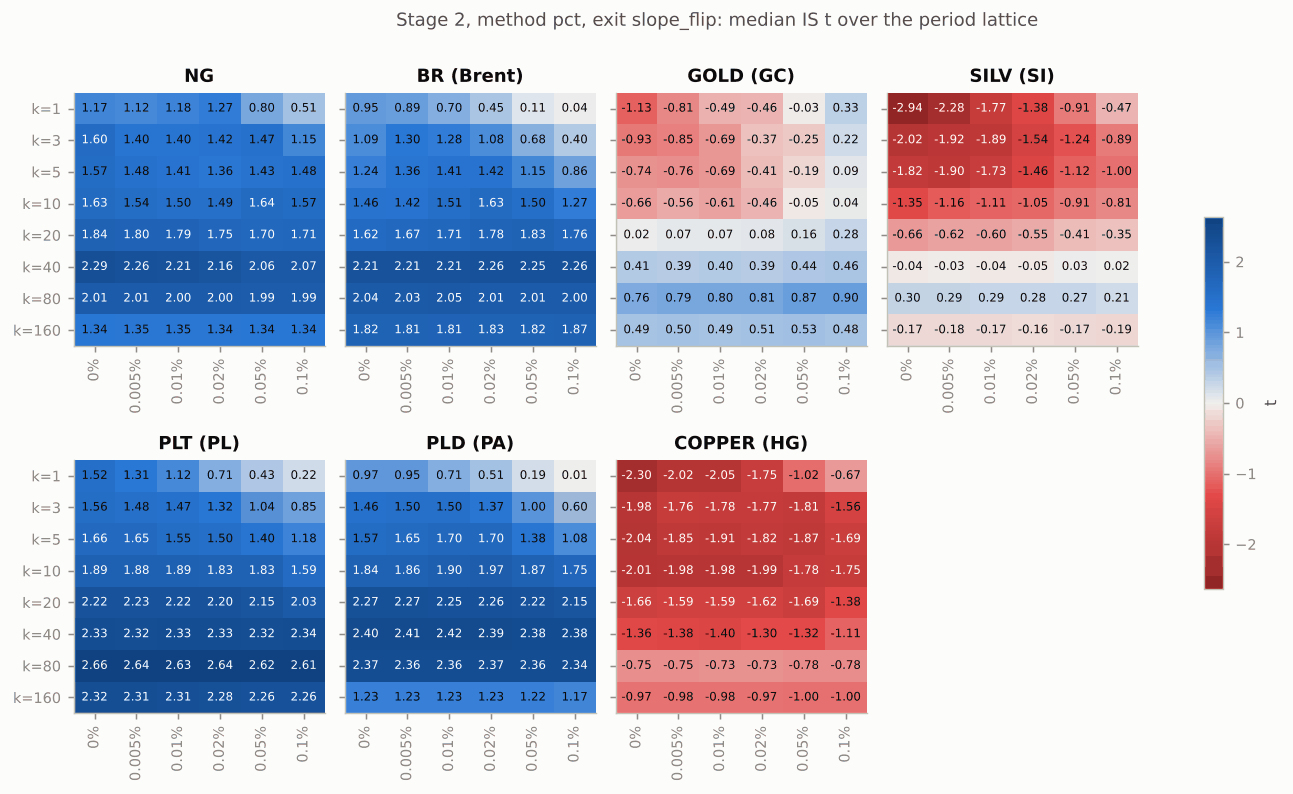

In [14]:
show("slope_sweep_pct_slope_flip.png")

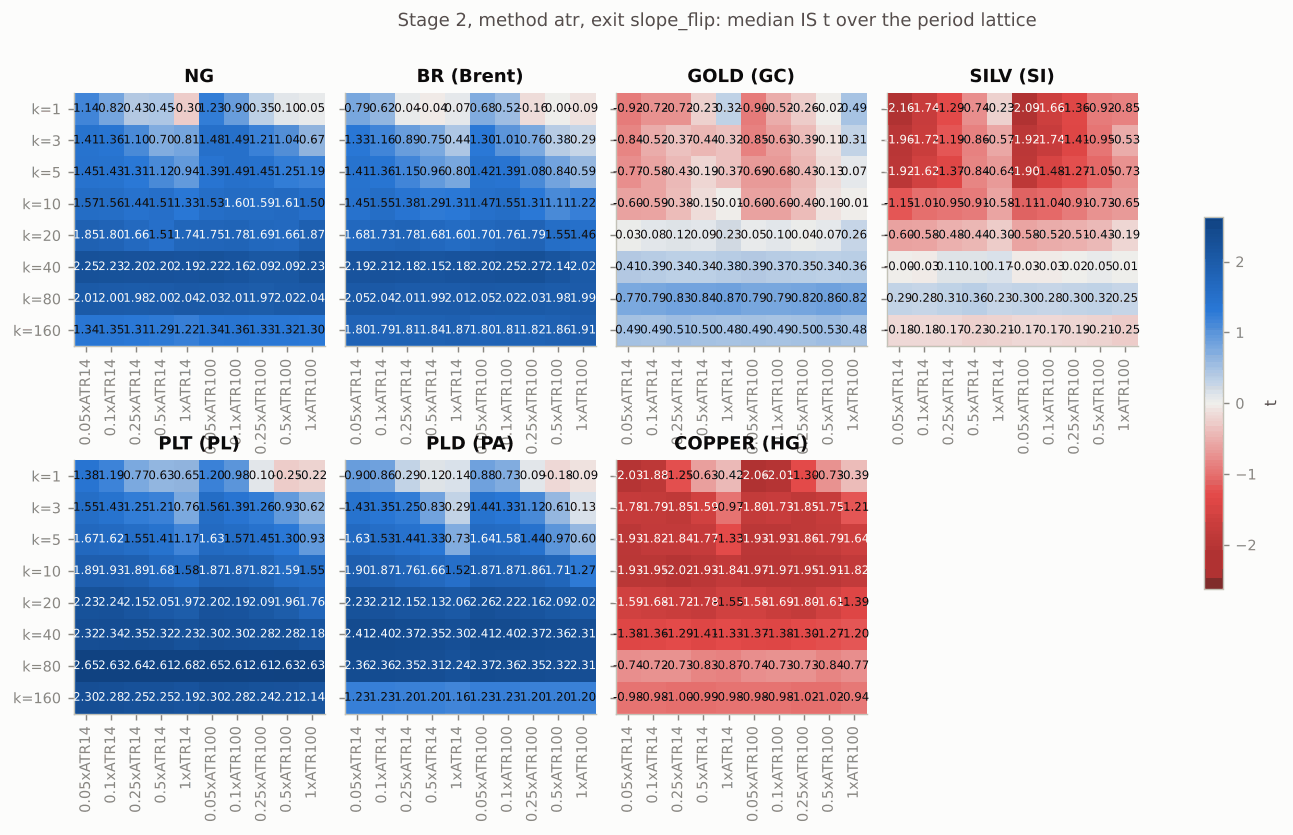

In [15]:
show("slope_sweep_atr_slope_flip.png")

## 8. Категория Fast ≥ Slow

In [16]:
rows = []
for (t, cat), g in s.groupby(["ticker", "category"]):
    rows.append({"инструмент": NAMES[t], "категория": cat, "IS t медиана": weighted(g, "is_t_median"),
                 "OOS t медиана": weighted(g, "oos_t_median")})
pd.DataFrame(rows).pivot(index="инструмент", columns="категория")

IS t медиана            OOS t медиана           
категория      fast<slow fast>=slow     fast<slow fast>=slow
инструмент                                                  
BR (Brent)         1.717      1.167         0.049      0.770
COPPER (HG)       -2.696     -2.078        -1.325     -1.327
GOLD (GC)         -0.612     -0.185         1.314      1.509
NG                 1.287      1.473         0.828      0.266
PLD (PA)           1.545      2.205        -0.304      0.502
PLT (PL)           2.030      2.348        -0.391     -0.220
SILV (SI)         -1.828     -1.085         0.879      0.605

## 9. Рейтинг, лучшие параметры, независимая выборка

Лучшая по IS-плато конфигурация каждого инструмента (этап 3) с метриками IS и OOS, Sharpe/Sortino дневного
PnL одного контракта (VectorBT), Monte Carlo и поправкой Холма:

In [17]:
fz = table("finalists.csv")
f3 = fz[(fz["stage"] == "stage3") & (fz["tag"] == "overall")].set_index("ticker").loc[INF + ["wti"]]
cols = ["fast_type", "fast_period", "slow_type", "slow_period", "slope", "model", "category", "is_trades", "is_t",
        "is_plateau_t", "is_pnl", "oos_trades", "oos_pnl", "oos_profit_factor", "oos_win_rate", "oos_t", "oos_p",
        "oos_p_holm", "oos_avg_trade_ticks", "oos_avg_hours", "oos_max_dd", "oos_max_loss_streak", "is_sharpe",
        "oos_sharpe", "oos_sortino", "mc_oos_p_loss", "mc_oos_max_dd_p95"]
f3[cols]

,fast_type,fast_period,slow_type,slow_period,slope,model,category,is_trades,is_t,is_plateau_t,is_pnl,oos_trades,oos_pnl,oos_profit_factor,oos_win_rate,oos_t,oos_p,oos_p_holm,oos_avg_trade_ticks,oos_avg_hours,oos_max_dd,oos_max_loss_streak,is_sharpe,oos_sharpe,oos_sortino,mc_oos_p_loss,mc_oos_max_dd_p95
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,
ng,VWMA,21,EMA,42,pct k=40 eps=0%,slope_flip,fast<slow,2033.000,4.077,4.187,2063.700,911.000,155.500,1.075,0.319,0.526,0.299,0.928,1.707,13.050,284.700,14.000,1.952,0.387,0.523,0.297,495.105
br,WMA,91,VWMA,200,atr k=40 eps=0.25 atr=100,slope_flip,fast<slow,1694.000,3.823,3.677,2441.500,785.000,42.700,1.011,0.344,0.090,0.464,0.928,0.544,34.441,685.300,11.000,1.128,0.020,0.030,0.470,986.670
gold,SSMA,61,VWMA,206,pct k=80 eps=0.1%,slope_flip,fast<slow,1132.000,2.299,2.256,1431.550,480.000,1355.300,1.202,0.354,1.084,0.139,0.837,28.235,55.180,836.600,13.000,0.650,0.554,0.924,0.141,1663.120
silv,VWMA,98,TMA,25,pct k=80 eps=0%,slope_flip,fast>=slow,3360.000,2.141,2.272,289.600,1389.000,256.400,1.116,0.359,0.732,0.232,0.928,1.846,11.284,279.600,11.000,0.654,0.308,0.631,0.237,509.915
plt,TMA,20,VWMA,112,pct k=80 eps=0%,slope_flip,fast<slow,1231.000,3.807,3.744,3461.500,588.000,965.000,1.160,0.391,0.948,0.172,0.858,16.412,30.849,532.200,11.000,1.188,0.568,0.927,0.175,1407.750
pld,WMA,73,WMA,50,pct k=40 eps=0.01%,slope_flip,fast>=slow,1699.000,4.286,4.220,6782.340,690.000,942.680,1.218,0.386,1.384,0.083,0.584,136.620,10.894,458.160,12.000,1.197,1.173,1.868,0.080,855.733
copper,VWMA,16,WMA,16,pct k=1 eps=0.1%,slope_flip,fast>=slow,143.000,1.387,1.631,43.950,16.000,4.870,1.307,0.562,0.401,0.347,0.928,30.437,195.562,7.850,3.000,1.181,0.496,0.677,0.346,19.011
wti,TMA,7,VWMA,7,atr k=20 eps=0.05 atr=14,reverse_cross,fast>=slow,142.000,1.221,1.413,178.700,56.000,-56.700,0.746,0.411,-0.822,0.793,NaN,-10.125,2.265,70.200,4.000,2.282,-4.157,-5.326,0.797,188.005


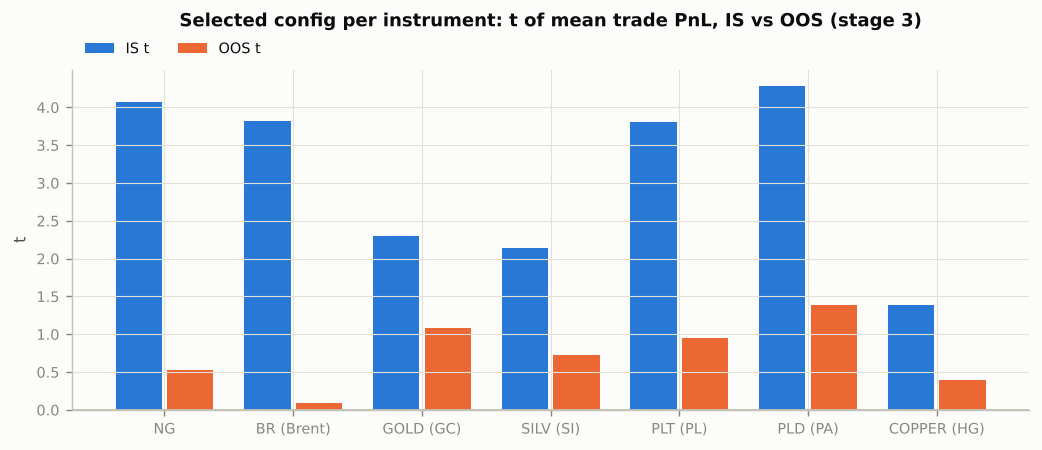

In [18]:
show("finalists_is_vs_oos.png")

In [19]:
display(Markdown("**Этап 1 (наклон k = 10) против этапа 3 (наклон подобран на IS): OOS t финалиста**"))
fz[(fz["tag"] == "overall") & fz["ticker"].isin(INF)].pivot(index="ticker", columns="stage", values="oos_t").loc[INF]

**Этап 1 (наклон k = 10) против этапа 3 (наклон подобран на IS): OOS t финалиста**

stage,stage1,stage3
ticker,,
ng,0.082,0.526
br,-0.176,0.090
gold,0.054,1.084
silv,1.462,0.732
plt,0.395,0.948
pld,0.098,1.384
copper,-0.253,0.401


In [20]:
rk = table("ranking_group_bests.csv")
rk3 = rk[(rk["stage"] == "stage3") & rk["ticker"].isin(INF)]
print(f"Лучших конфигураций групп: {len(rk3)}, с OOS t > 0: {(rk3['oos_t'] > 0).sum()}, "
      f"p < 0.05 без поправки: {(rk3['oos_p'] < 0.05).sum()}, q(BH) < 0.05: {(rk3['oos_q_bh'] < 0.05).sum()}, "
      f"минимальный q: {rk3['oos_q_bh'].min():.3f}")
show_cols = ["ticker", "fast_type", "fast_period", "slow_type", "slow_period", "method", "model", "is_plateau_t",
             "is_t", "oos_trades", "oos_t", "oos_pnl", "oos_profit_factor", "oos_p", "oos_q_bh"]
display(Markdown("**Рейтинг: по 3 лучших группы на инструмент (по IS-плато), с результатом на OOS**"))
rk3.sort_values("is_plateau_t", ascending=False).groupby("ticker").head(3).sort_values(["ticker", "is_plateau_t"],
                                                                                       ascending=[True, False])[show_cols]

Лучших конфигураций групп: 990, с OOS t > 0: 646, p < 0.05 без поправки: 57, q(BH) < 0.05: 0, минимальный q: 0.082


**Рейтинг: по 3 лучших группы на инструмент (по IS-плато), с результатом на OOS**

,ticker,fast_type,fast_period,slow_type,slow_period,method,model,is_plateau_t,is_t,oos_trades,oos_t,oos_pnl,oos_profit_factor,oos_p,oos_q_bh
1080,br,WMA,91,VWMA,200,atr,slope_flip,3.677,3.823,785.000,0.090,42.700,1.011,0.464,0.749
1081,br,TMA,84,WMA,242,atr,slope_flip,3.676,3.612,645.000,0.627,316.400,1.090,0.266,0.698
1082,br,SMA,62,VWMA,201,atr,slope_flip,3.579,3.564,768.000,0.307,139.200,1.037,0.379,0.713
1224,copper,VWMA,16,WMA,16,pct,slope_flip,1.631,1.387,16.000,0.401,4.870,1.307,0.347,0.709
1225,copper,VWMA,11,EMA,15,pct,slope_flip,1.554,1.517,15.000,-0.428,-4.870,0.724,0.662,0.852
1226,copper,VWMA,11,SSMA,5,pct,slope_flip,1.424,0.694,41.000,-0.921,-10.570,0.697,0.819,0.920
1350,gold,SSMA,61,VWMA,206,pct,slope_flip,2.256,2.299,480.000,1.084,1355.300,1.202,0.139,0.698
1351,gold,VWMA,3,VWMA,250,pct,slope_flip,2.253,2.228,448.000,1.065,1458.400,1.201,0.144,0.698
1352,gold,WMA,83,VWMA,205,pct,slope_flip,2.253,2.433,496.000,1.422,1802.200,1.258,0.078,0.698
1494,ng,VWMA,21,EMA,42,pct,slope_flip,4.187,4.077,911.000,0.526,155.500,1.075,0.299,0.698


In [21]:
display(Markdown("**Лучшие на OOS среди 990 групп (после отбора по IS) — для информации, q учитывает множественность**"))
rk3.sort_values("oos_q_bh").head(10)[show_cols]

**Лучшие на OOS среди 990 групп (после отбора по IS) — для информации, q учитывает множественность**

,ticker,fast_type,fast_period,slow_type,slow_period,method,model,is_plateau_t,is_t,oos_trades,oos_t,oos_pnl,oos_profit_factor,oos_p,oos_q_bh
1409,gold,SMA,3,EMA,56,pct,slope_flip,1.556,1.538,937.000,3.467,4595.100,1.496,0.000,0.082
1408,gold,TMA,3,EMA,56,pct,slope_flip,1.579,1.540,937.000,3.418,4547.900,1.487,0.000,0.082
1418,gold,SMA,3,SSMA,30,pct,slope_flip,1.519,1.502,919.000,3.479,4608.000,1.502,0.000,0.082
1415,gold,TMA,3,SSMA,30,pct,slope_flip,1.528,1.516,921.000,3.476,4611.700,1.502,0.000,0.082
1407,gold,VWMA,4,EMA,56,pct,slope_flip,1.586,1.632,937.000,3.267,4318.700,1.460,0.001,0.111
1412,gold,VWMA,3,SSMA,31,pct,slope_flip,1.542,1.491,905.000,3.155,4168.300,1.448,0.001,0.137
1416,gold,WMA,6,SSMA,31,pct,slope_flip,1.527,1.517,901.000,3.105,4063.000,1.439,0.001,0.139
1406,gold,WMA,46,EMA,20,pct,slope_flip,1.587,1.717,1263.000,2.774,3314.800,1.347,0.003,0.309
1382,gold,WMA,46,TMA,32,pct,slope_flip,1.733,1.771,1236.000,2.778,3457.000,1.357,0.003,0.309
1384,gold,VWMA,6,WMA,32,atr,slope_flip,1.714,1.658,1487.000,2.660,3398.800,1.298,0.004,0.391


### Карты Fast × Slow и устойчивости (слой лучшей конфигурации)

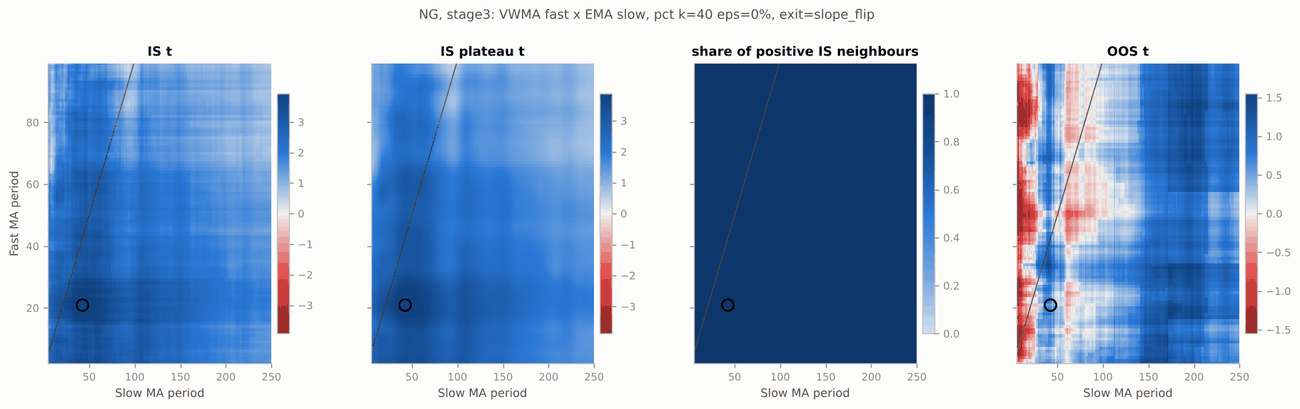

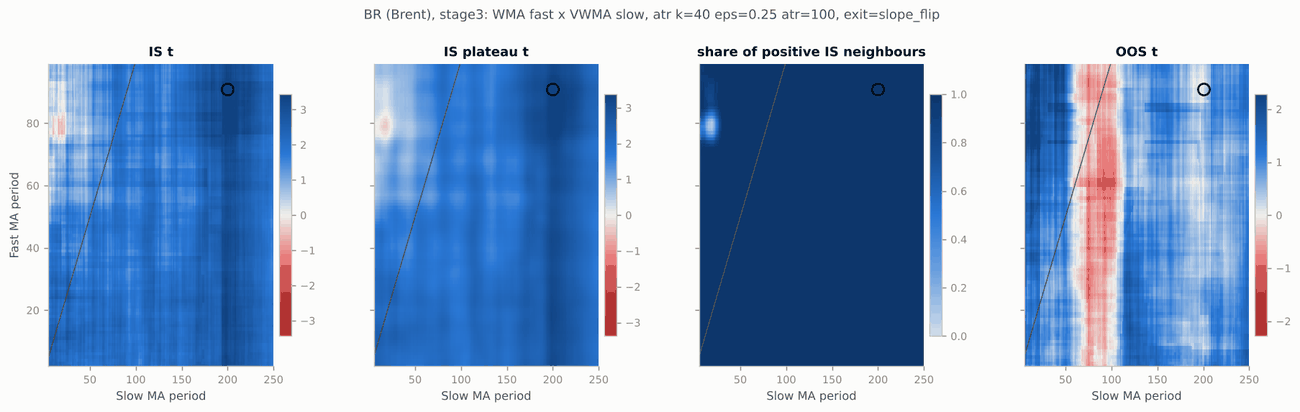

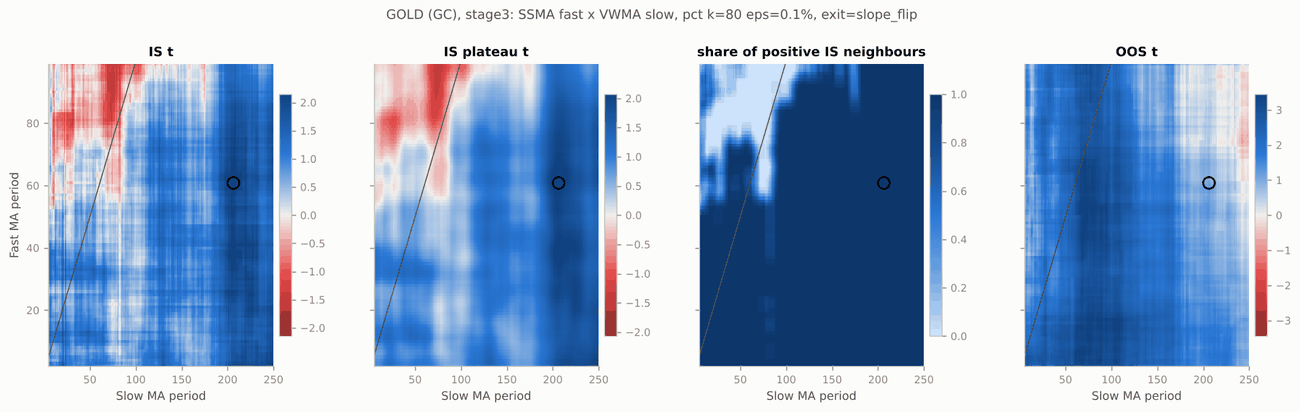

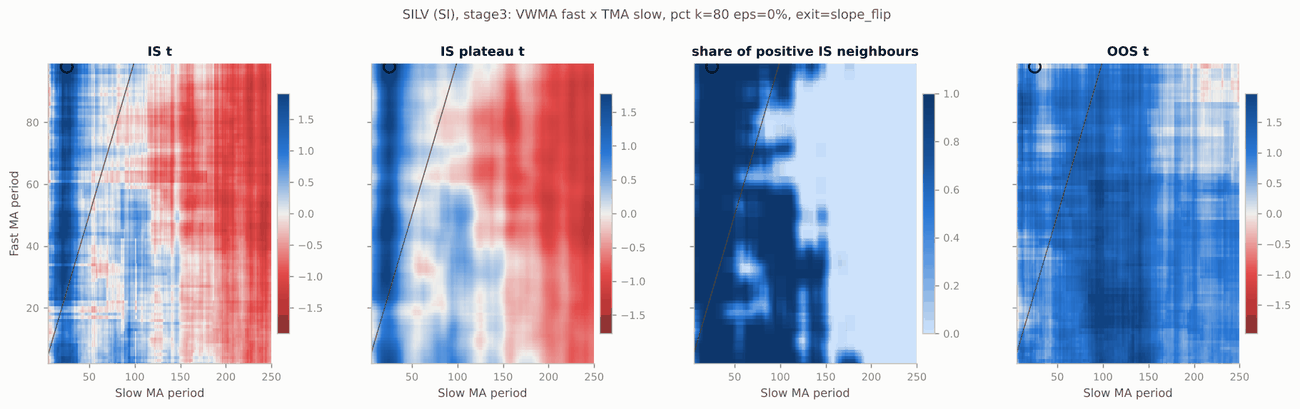

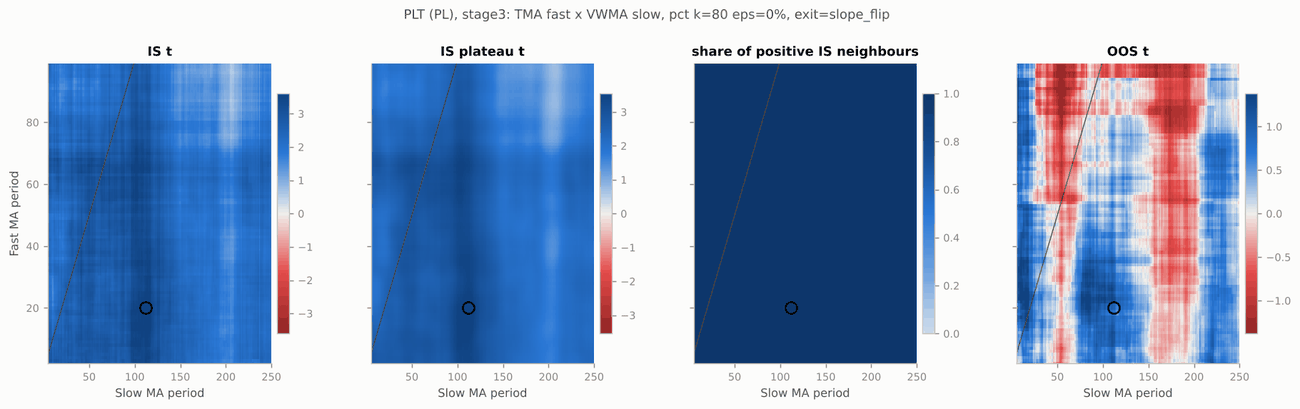

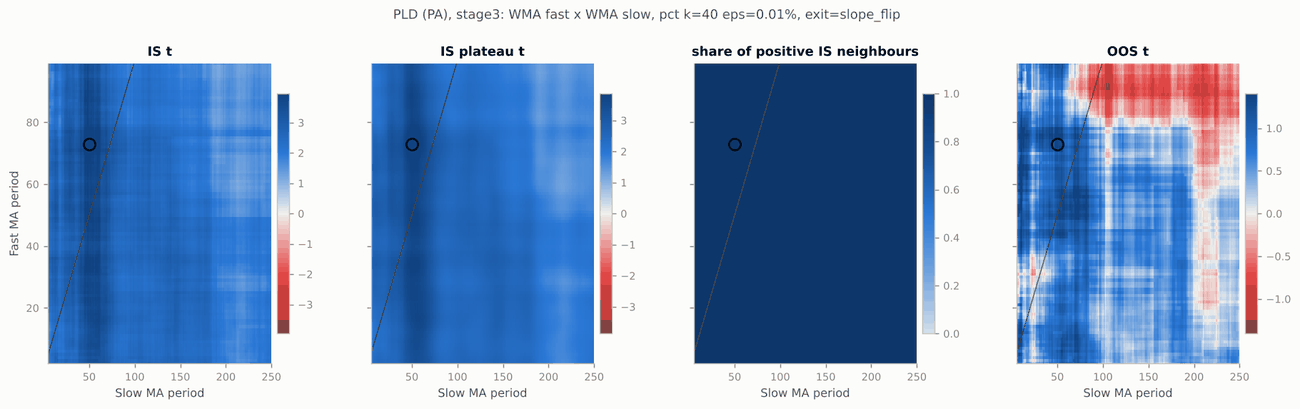

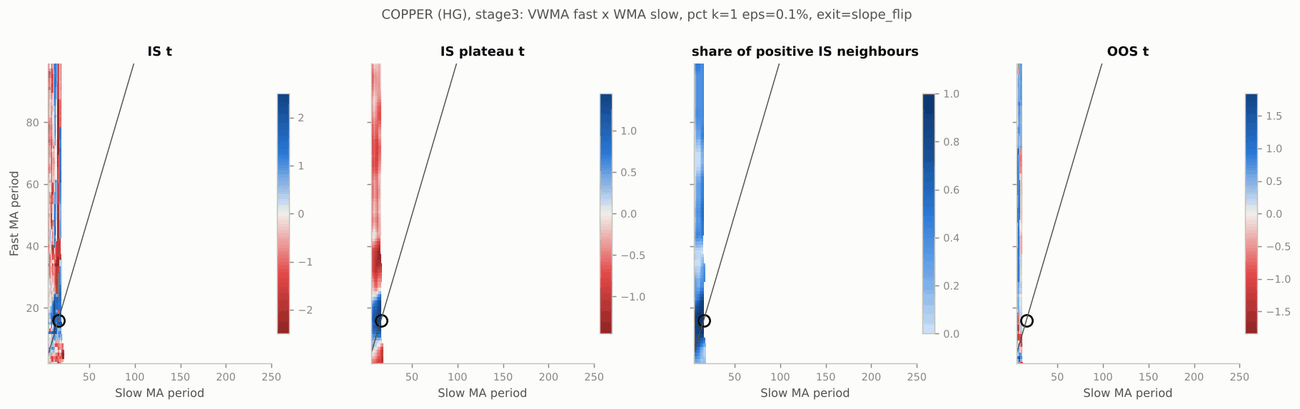

In [22]:
for t in INF:
    show(f"heatmap_stage3_{t}.png")

### Кривые капитала, распределения сделок, результаты по месяцам и годам

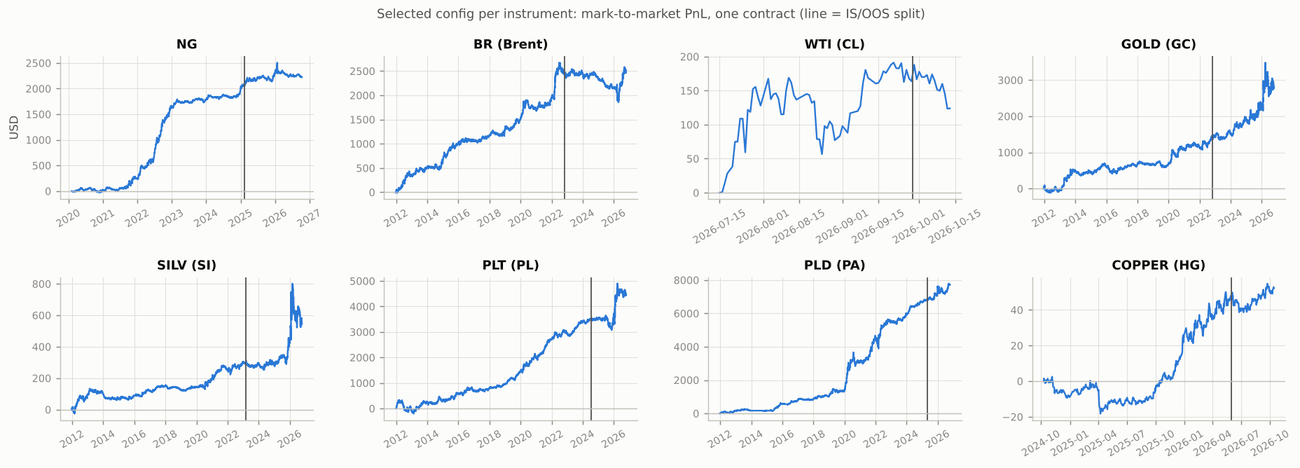

In [23]:
show("equity_finalists.png")

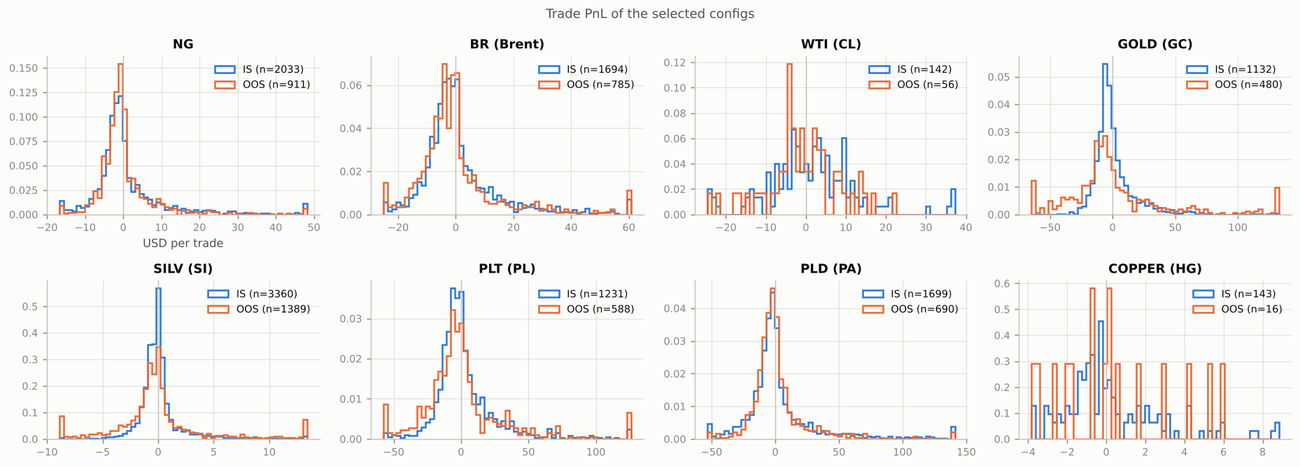

In [24]:
show("trade_distributions.png")

In [25]:
yearly = table("finalist_yearly_pnl.csv").pivot(index="year", columns="ticker", values="pnl")
yearly[[t for t in INF + ["wti"] if t in yearly.columns]].round(0)

ticker,ng,br,gold,silv,plt,pld,copper,wti
year,,,,,,,,
2011,NaN,-3.000,30.000,11.000,NaN,NaN,NaN,NaN
2012,NaN,358.000,-54.000,85.000,-77.000,159.000,NaN,NaN
2013,NaN,146.000,530.000,1.000,273.000,8.000,NaN,NaN
2014,NaN,86.000,-78.000,-27.000,103.000,NaN,NaN,NaN
2015,NaN,414.000,162.000,19.000,257.000,427.000,NaN,NaN
2016,NaN,85.000,-52.000,28.000,135.000,190.000,NaN,NaN
2017,NaN,81.000,91.000,37.000,92.000,22.000,NaN,NaN
2018,NaN,118.000,46.000,-31.000,163.000,195.000,NaN,NaN
2019,NaN,212.000,-38.000,21.000,491.000,330.000,NaN,NaN


In [26]:
monthly = table("finalist_monthly_pnl.csv")
display(Markdown("**PnL по месяцам, PLD (остальные инструменты — в `tables/finalist_monthly_pnl.csv`)**"))
monthly[monthly["ticker"] == "pld"].drop(columns="ticker").set_index("year").round(0)

**PnL по месяцам, PLD (остальные инструменты — в `tables/finalist_monthly_pnl.csv`)**

,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,-0.000,43.000,-6.000,59.000,-36.000,2.000,-11.000,47.000,-29.000,-17.000,28.000,79.000
2013,-10.000,40.000,-6.000,-6.000,41.000,-19.000,44.000,-6.000,-3.000,-34.000,NaN,-32.000
2015,NaN,-3.000,NaN,NaN,NaN,NaN,NaN,177.000,NaN,119.000,133.000,NaN
2016,-24.000,-11.000,NaN,-23.000,6.000,32.000,NaN,109.000,10.000,18.000,5.000,68.000
2017,62.000,33.000,-32.000,-26.000,-15.000,14.000,-6.000,34.000,-23.000,-19.000,9.000,-8.000
2018,78.000,46.000,-10.000,131.000,-30.000,-40.000,27.000,7.000,6.000,54.000,-20.000,-53.000
2019,151.000,127.000,146.000,17.000,-105.000,27.000,-125.000,40.000,59.000,-11.000,-9.000,12.000
2020,483.000,375.000,743.000,-291.000,424.000,51.000,246.000,-333.000,-26.000,154.000,-83.000,0.000
2021,54.000,-122.000,40.000,125.000,76.000,-3.000,184.000,248.000,126.000,395.000,201.000,101.000


## 10. Устойчивость: walk-forward, польза отбора, PBO, Monte Carlo

In [27]:
wf = table("walk_forward_summary.csv")
wf1 = wf[(wf["stage"] == "stage1") & (wf["scope"] == "all")].set_index("ticker")
wf1["p_holm"] = A.holm(wf1["pooled_p"])
wf1

,stage,scope,test_years,positive_years,test_pnl,test_trades,pooled_t,pooled_p,p_holm
ticker,,,,,,,,,
br,stage1,all,13,9,881.500,6140.000,1.154,0.124,0.160
gold,stage1,all,13,6,1887.500,3582.000,1.404,0.080,0.160
ng,stage1,all,4,4,874.300,1737.000,2.561,0.005,0.028
pld,stage1,all,13,10,3019.060,7442.000,2.155,0.016,0.062
plt,stage1,all,13,12,2935.000,13484.000,2.603,0.005,0.028
silv,stage1,all,13,9,862.300,3459.000,2.106,0.018,0.062


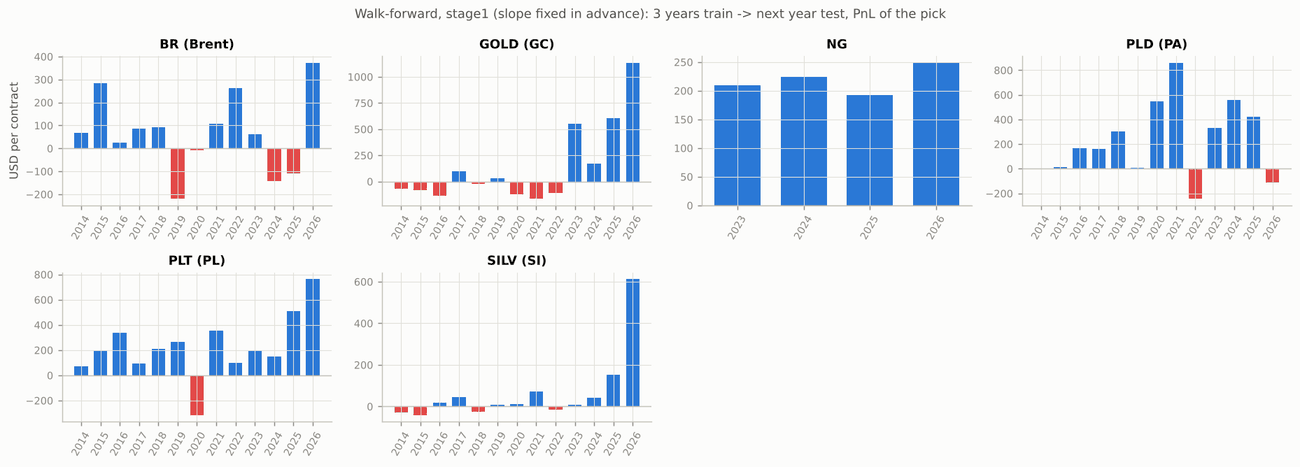

In [28]:
show("walk_forward_stage1.png")

In [29]:
sk = table("selection_skill.csv")
w = sk[sk["kind"] == "walk_forward"]
display(w.groupby(["stage", "ticker"])[["selected_percentile", "selected_t", "median_config_t"]].mean().unstack(0))
for st in ("stage1", "stage3"):
    v = w[w["stage"] == st]["selected_percentile"].dropna()
    print(f"{st}: средний перцентиль выбора {v.mean():.3f} по {len(v)} тестовым годам, "
          f"z = {(v.mean() - 0.5) / (np.sqrt(1 / 12) / np.sqrt(len(v))):.2f}")

selected_percentile        selected_t        median_config_t       
stage               stage1 stage3     stage1 stage3          stage1 stage3
ticker                                                                    
br                   0.492  0.574      0.198  0.502           0.226  0.278
gold                 0.584  0.699      0.151  0.401          -0.201 -0.080
ng                   0.871  0.659      1.345  0.813           0.608  0.589
pld                  0.645  0.648      0.888  0.999           0.520  0.584
plt                  0.739  0.523      1.053  0.626           0.446  0.524
silv                 0.700  0.560      0.198 -0.137          -0.471 -0.343

stage1: средний перцентиль выбора 0.646 по 68 тестовым годам, z = 4.17
stage3: средний перцентиль выбора 0.603 по 67 тестовым годам, z = 2.92


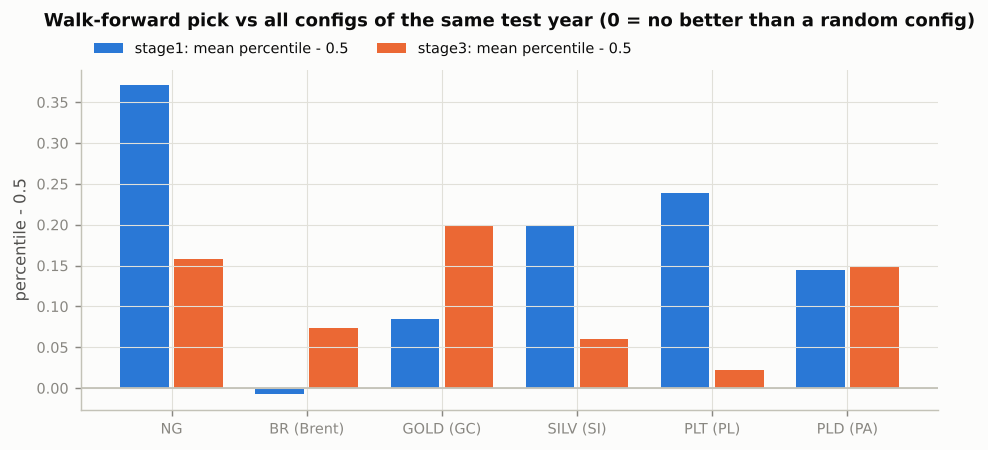

In [30]:
show("selection_skill.png")

stage,stage1,stage3
ticker,,
br,0.567,0.528
gold,0.230,0.242
ng,0.200,0.350
pld,0.266,0.067
plt,0.452,0.504
silv,0.159,0.131


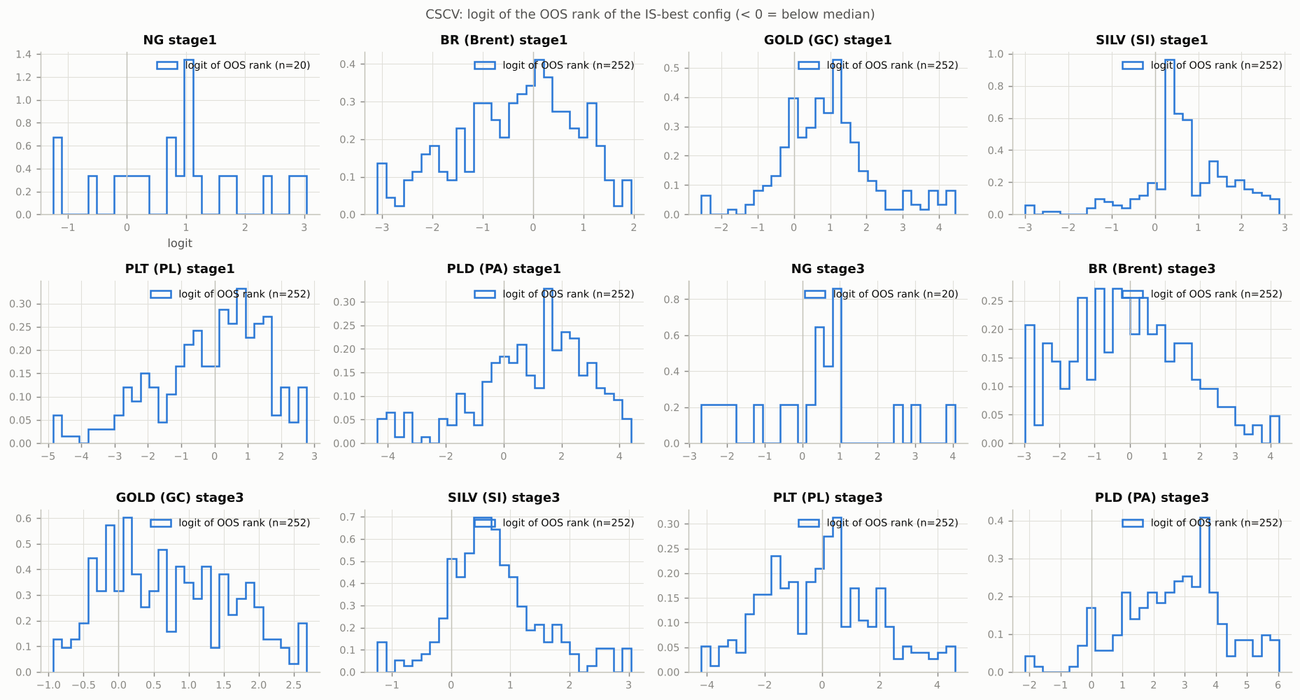

In [31]:
display(table("pbo.csv").pivot(index="ticker", columns="stage", values="pbo"))
show("pbo_logits.png")

## 11. Межрыночная проверка (этап 1, одинаковые правила)

In [32]:
cm = summary["cross_market"]
print("Конфигураций, валидных на всех рынках:", cm["configs_common"])
print("Доля с OOS t > 0:", {k: round(v, 2) for k, v in cm["positive_rate"].items()})
print("Положительны на OOS везде:", cm["all_positive_oos"], "при ожидании для независимых рынков",
      round(cm["all_positive_oos_expected"]))
print("Положительны на IS везде:", cm["is_positive_everywhere"], "-> их доля с OOS t > 0:",
      {k: round(v, 2) for k, v in cm["oos_positive_rate_given_is_positive_everywhere"].items()})
display(Markdown("**Честный отбор только по IS (худший рынок по IS-плато) и результат на OOS**"))
table("cross_market_is_selected.csv").head(10)

Конфигураций, валидных на всех рынках: 3451517
Доля с OOS t > 0: {'ng': 0.84, 'br': 0.54, 'gold': 0.81, 'silv': 0.74, 'plt': 0.31, 'pld': 0.41, 'copper': 0.02}
Положительны на OOS везде: 5831 при ожидании для независимых рынков 2861
Положительны на IS везде: 57148 -> их доля с OOS t > 0: {'ng': 0.73, 'br': 0.93, 'gold': 1.0, 'silv': 0.97, 'plt': 0.71, 'pld': 0.38, 'copper': 0.05}


**Честный отбор только по IS (худший рынок по IS-плато) и результат на OOS**

,slow_type,slow_period,method,fast_type,fast_period,model,min_is_plateau_t,ng_is_t,ng_oos_t,br_is_t,br_oos_t,gold_is_t,gold_oos_t,silv_is_t,silv_oos_t,plt_is_t,plt_oos_t,pld_is_t,pld_oos_t,copper_is_t,copper_oos_t,oos_positive_instruments,oos_mean_t
0,TMA,84,pct,WMA,92,slope_flip,0.844,1.505,-0.156,1.667,1.197,0.726,1.680,0.726,1.403,2.784,0.078,2.400,-0.823,0.896,-0.046,4,0.476
1,TMA,85,pct,WMA,91,slope_flip,0.830,1.345,-0.440,1.754,0.699,0.804,1.828,0.795,1.461,2.404,-0.165,2.472,-0.953,1.021,-0.847,3,0.226
2,TMA,84,pct,WMA,93,slope_flip,0.824,1.472,-0.166,1.551,1.195,1.069,1.666,0.775,1.281,2.868,-0.134,2.416,-0.849,0.944,-0.080,3,0.416
3,TMA,84,pct,WMA,91,slope_flip,0.822,1.466,-0.150,1.625,1.258,0.739,1.593,0.768,1.480,2.762,0.014,2.410,-0.865,0.926,-0.069,4,0.466
4,TMA,84,pct,WMA,81,slope_flip,0.815,2.139,-0.288,1.246,1.192,0.871,0.979,0.522,1.339,2.440,0.349,2.499,-0.200,0.757,0.202,5,0.510
5,TMA,84,pct,WMA,89,slope_flip,0.812,1.464,-0.069,1.437,0.951,0.835,1.591,0.590,1.491,2.595,0.284,2.421,-0.739,0.874,-0.057,4,0.493
6,TMA,85,pct,WMA,90,slope_flip,0.810,1.352,-0.432,1.658,0.632,0.714,1.973,0.675,1.414,2.356,-0.120,2.521,-0.871,1.009,-0.849,3,0.250
7,TMA,84,pct,WMA,88,slope_flip,0.806,1.549,0.045,1.356,0.989,0.833,1.344,0.485,1.509,2.640,0.273,2.437,-0.643,0.860,0.069,6,0.512
8,TMA,85,pct,WMA,92,slope_flip,0.802,1.369,-0.442,1.783,0.612,0.790,1.911,0.773,1.385,2.424,-0.124,2.430,-0.909,0.998,-0.826,3,0.230
9,TMA,84,pct,WMA,90,slope_flip,0.800,1.492,-0.139,1.495,1.203,0.632,1.752,0.631,1.437,2.697,0.061,2.450,-0.777,0.920,-0.044,4,0.499


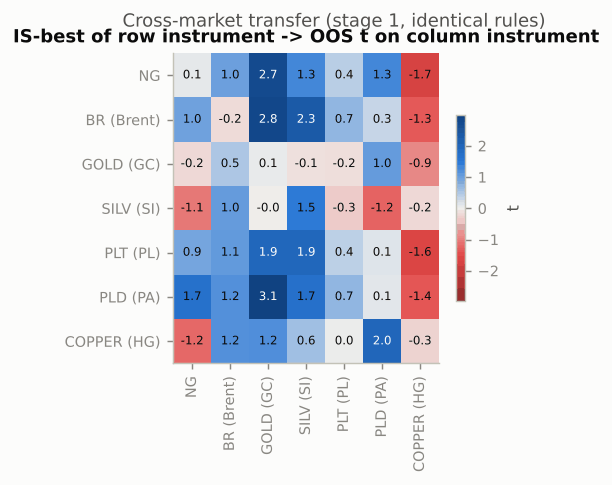

In [33]:
show("cross_market_transfer.png")

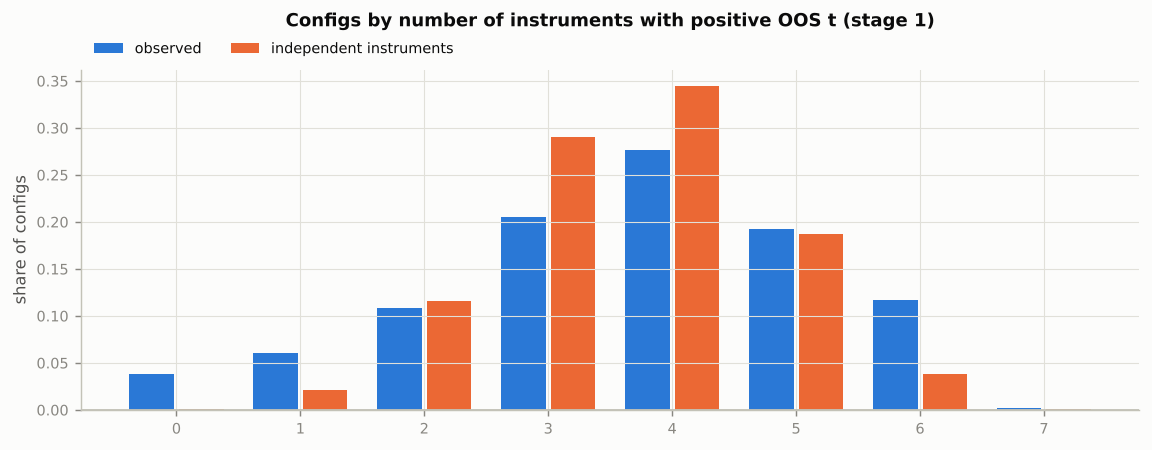

In [34]:
show("cross_market_counts.png")

## 12. Исследователь: любая конфигурация

Полные сетки лежат в `research/ma_cross_slope_5m/grid/`: `stage3_<тикер>.parquet` и `stage1_<тикер>.parquet` —
все 3 471 552 конфигурации инструмента (сделки, PnL, t, Profit Factor, win rate, просадка на IS и OOS, IS-плато);
`stage2_<тикер>.parquet` — решётка периодов под каждой из 128 настроек наклона. Ниже — выборка из сетки, карта
Fast × Slow для любого слоя и пересчёт любой конфигурации на свечах через VectorBT.

In [35]:
grid = load_full_grid("pld")
print(grid.shape)
q = grid[(grid["model"] == "slope_flip") & (grid["is_trades"] >= 100)]
q.sort_values("is_plateau_t", ascending=False).head(10)

(3471552, 19)


,slow_type,slow_period,method,fast_type,fast_period,model,is_trades,is_pnl,is_t,is_profit_factor,is_win_rate,is_max_dd,oos_trades,oos_pnl,oos_t,oos_profit_factor,oos_win_rate,oos_max_dd,is_plateau_t
1263559,WMA,50,pct,WMA,73,slope_flip,1699,6782.300,4.290,1.550,0.386,737.600,690,942.700,1.380,1.220,0.386,458.200,4.220
1265911,WMA,51,pct,WMA,73,slope_flip,1684,6619.300,4.170,1.540,0.386,832.500,688,875.300,1.290,1.200,0.376,495.200,4.210
1263557,WMA,50,pct,WMA,72,slope_flip,1700,6824.900,4.260,1.550,0.386,739.900,688,962.000,1.410,1.220,0.391,459.800,4.210
1265909,WMA,51,pct,WMA,72,slope_flip,1686,6669.900,4.150,1.530,0.387,834.900,686,893.600,1.310,1.210,0.383,474.700,4.200
1261207,WMA,49,pct,WMA,73,slope_flip,1717,7144.800,4.460,1.580,0.392,803.700,694,931.600,1.370,1.220,0.383,489.200,4.190
1268263,WMA,52,pct,WMA,73,slope_flip,1669,6865.400,4.340,1.570,0.380,839.200,684,903.700,1.330,1.210,0.370,510.800,4.190
1260843,WMA,49,pct,SMA,87,slope_flip,1592,5759.800,4.460,1.570,0.396,378.900,624,630.300,1.140,1.190,0.372,332.000,4.180
1261205,WMA,49,pct,WMA,72,slope_flip,1719,7147.600,4.410,1.570,0.392,806.100,693,934.400,1.370,1.220,0.388,516.700,4.180
1268261,WMA,52,pct,WMA,72,slope_flip,1671,6845.600,4.270,1.550,0.381,841.600,682,922.300,1.360,1.210,0.375,489.700,4.180
1263561,WMA,50,pct,WMA,74,slope_flip,1696,6662.300,4.210,1.540,0.381,732.300,693,936.100,1.380,1.220,0.384,435.100,4.180


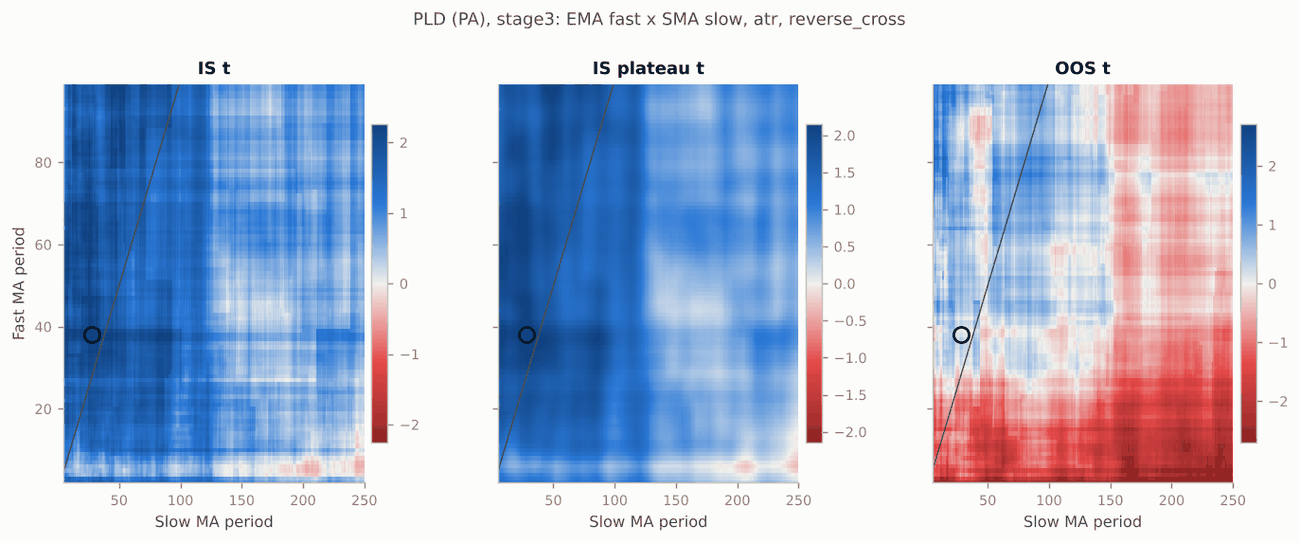

In [36]:
def slice_maps(grid, ticker, fast_type, slow_type, method, model, stage="stage3"):
    """IS t, IS plateau and OOS t over Fast x Slow for one types/method/model layer."""
    g = grid[(grid["fast_type"] == fast_type) & (grid["slow_type"] == slow_type)
             & (grid["method"] == method) & (grid["model"] == model)]
    piv = {c: g.pivot(index="fast_period", columns="slow_period", values=c) for c in ("is_t", "is_plateau_t", "oos_t")}
    best = g.loc[g["is_plateau_t"].idxmax()]
    path = TMP / f"slice_{ticker}_{fast_type}_{slow_type}_{method}_{model}.png"
    P.period_heatmaps([("IS t", piv["is_t"].to_numpy()), ("IS plateau t", piv["is_plateau_t"].to_numpy()),
                       ("OOS t", piv["oos_t"].to_numpy())],
                      list(piv["is_t"].index), list(piv["is_t"].columns),
                      (best["fast_period"], best["slow_period"]),
                      f"{NAMES[ticker]}, {stage}: {fast_type} fast x {slow_type} slow, {method}, {model}", path)
    show(path.name, folder=TMP)


slice_maps(grid, "pld", "EMA", "SMA", "atr", "reverse_cross")

**PLD (PA): WMA73 / WMA50, pct k=40 eps=0.01%, exit=slope_flip** — сделки VectorBT совпадают с ядром: True

,сделок,"PnL, $",win %,PF,t,ср. часов,trading_days_per_year,sharpe,sortino,mtm_max_dd
IS,1699.000,6782.340,38.611,1.550,4.286,42.381,227.363,1.197,2.257,827.880
OOS,690.000,942.680,38.551,1.218,1.384,10.894,318.912,1.173,1.868,472.541
все,2389.000,7725.020,38.594,1.464,4.482,33.287,236.390,1.191,2.179,827.880


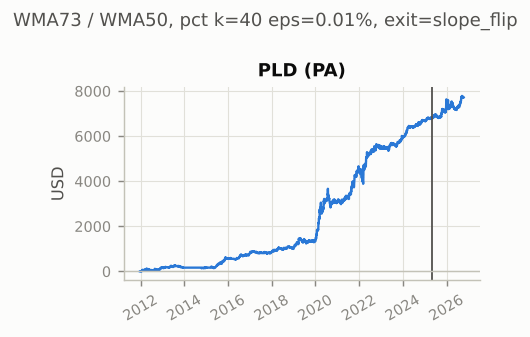

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,-0.000,43.000,-6.000,59.000,-36.000,2.000,-11.000,47.000,-29.000,-17.000,28.000,79.000
2013,-10.000,40.000,-6.000,-6.000,41.000,-19.000,44.000,-6.000,-3.000,-34.000,NaN,-32.000
2015,NaN,-3.000,NaN,NaN,NaN,NaN,NaN,177.000,NaN,119.000,133.000,NaN
2016,-24.000,-11.000,NaN,-23.000,6.000,32.000,NaN,109.000,10.000,18.000,5.000,68.000
2017,62.000,33.000,-32.000,-26.000,-15.000,14.000,-6.000,34.000,-23.000,-19.000,9.000,-8.000
2018,78.000,46.000,-10.000,131.000,-30.000,-40.000,27.000,7.000,6.000,54.000,-20.000,-53.000
2019,151.000,127.000,146.000,17.000,-105.000,27.000,-125.000,40.000,59.000,-11.000,-9.000,12.000
2020,483.000,375.000,743.000,-291.000,424.000,51.000,246.000,-333.000,-26.000,154.000,-83.000,0.000
2021,54.000,-122.000,40.000,125.000,76.000,-3.000,184.000,248.000,126.000,395.000,201.000,101.000


In [37]:
def inspect(ticker, fast_type, fast_period, slow_type, slow_period, method, model, stage="stage3"):
    """Re-run one config on the 5m candles: trades from the kernel, equity and stats from vectorbt."""
    slope = Slope(**grid_meta(stage, ticker)["slopes"][f"{method}/{model}"])
    cfg = F.Config(fast_type, fast_period, slow_type, slow_period, slope, EXIT_MODELS.index(model))
    ins = load_instrument(ticker)
    tr = F.trades(ins, cfg)
    pf = F.portfolio(ins, cfg)
    daily = F.daily_pnl(pf)
    days = pd.to_datetime(daily.index)
    rows = {}
    for name, part in (("IS", tr[tr["sample"] == "is"]), ("OOS", tr[tr["sample"] == "oos"]), ("все", tr)):
        pnl = part["pnl"].to_numpy()
        n = len(pnl)
        rows[name] = {"сделок": n, "PnL, $": pnl.sum(), "win %": 100 * np.mean(pnl > 0) if n else np.nan,
                      "PF": pnl[pnl > 0].sum() / -pnl[pnl < 0].sum() if (pnl < 0).any() else np.nan,
                      "t": float(A.t_stat(n, pnl.sum(), (pnl ** 2).sum())), "ср. часов": part["hours"].mean()}
    for name, part in (("IS", daily[days < ins.split_time.normalize()]),
                       ("OOS", daily[days >= ins.split_time.normalize()]), ("все", daily)):
        rows[name].update(F.risk_metrics(part))
    closed = pf.trades.records_readable
    closed = closed[closed["Status"] == "Closed"]
    same = len(closed) == len(tr) and np.allclose(closed["PnL"].to_numpy(), tr["pnl"].to_numpy())
    display(Markdown(f"**{NAMES[ticker]}: {cfg.label}** — сделки VectorBT совпадают с ядром: {same}"))
    display(pd.DataFrame(rows).T)
    eq = daily.cumsum()
    path = TMP / f"equity_{ticker}.png"
    P.small_multiples_lines({NAMES[ticker]: [("MTM PnL, USD/contract", pd.to_datetime(eq.index), eq.to_numpy())]},
                            cfg.label, "USD", path, vlines={NAMES[ticker]: ins.split_time}, ncols=1)
    show(path.name, folder=TMP, width=900)
    monthly, _ = F.calendar(tr)
    display(monthly.round(0))
    return tr, pf


tr, pf = inspect("pld", "WMA", 73, "WMA", 50, "pct", "slope_flip")

**NG: EMA9 / SMA100, atr k=40 eps=0.05 atr=14, exit=reverse_cross** — сделки VectorBT совпадают с ядром: True

,сделок,"PnL, $",win %,PF,t,ср. часов,trading_days_per_year,sharpe,sortino,mtm_max_dd
IS,20807.000,-811.000,28.519,0.936,-2.009,1.066,253.219,-0.910,-1.272,835.500
OOS,8970.000,84.000,26.087,1.021,0.367,0.811,311.624,0.311,0.529,206.198
все,29777.000,-727.000,27.787,0.957,-1.566,0.989,267.770,-0.631,-0.914,897.000


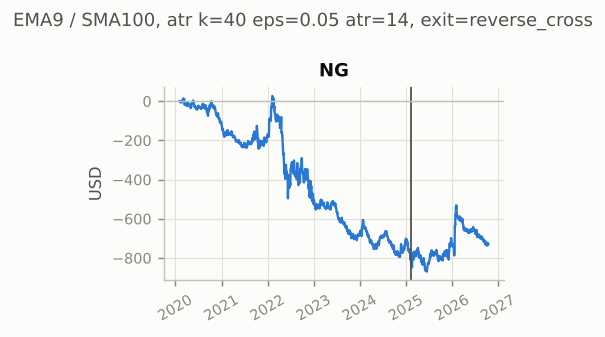

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2020,NaN,10.000,-34.000,-9.000,9.000,1.000,-7.000,-2.000,7.000,-7.000,-46.000,-29.000
2021,-67.000,10.000,-15.000,-23.000,-13.000,3.000,6.000,-2.000,40.000,-51.000,8.000,41.000
2022,141.000,-26.000,-36.000,-121.000,-148.000,-53.000,92.000,-72.000,52.000,-32.000,-105.000,-47.000
2023,-8.000,31.000,-39.000,-0.000,33.000,-54.000,-47.000,-10.000,-52.000,-10.000,-16.000,16.000
2024,48.000,-47.000,-29.000,-28.000,7.000,33.000,30.000,-53.000,-45.000,-11.000,25.000,51.000
2025,-72.000,-36.000,46.000,-57.000,-36.000,26.000,57.000,4.000,-31.000,22.000,-6.000,55.000
2026,185.000,-59.000,-40.000,-12.000,-4.000,-1.000,-25.000,-18.000,-24.000,-0.000,NaN,NaN


In [38]:
tr, pf = inspect("ng", "EMA", 9, "SMA", 100, "atr", "reverse_cross")

## 13. Выводы

1. Устойчивого преимущества у конкретных параметров нет: после поправок на множественное тестирование ни одна
   конфигурация не подтверждается на OOS, а лучшие по IS в среднем не лучше случайной на NG, BR, GOLD и SILV.
2. Воспроизводимые закономерности касаются семейств правил: удержание до разворота наклона лучше быстрого выхода;
   горизонт наклона 40–80 баров лучше коротких; нейтральная зона и метод её определения почти не важны; медленная
   EMA/SSMA/WMA немного лучше SMA/TMA/VWMA.
3. Знак результата задаёт режим рынка: без издержек это преимущество трендовой экспозиции, а не параметров.
4. Самый сильный результат — ежегодный переотбор (walk-forward): плюс на всех 6 рынках с длинной историей, значимо на
   NG и PLT; но средняя сделка на NG, BR, SILV — 0,5–2 тика, поэтому без учёта комиссий и спреда выводы о
   торгуемости делать нельзя.

Воспроизведение всех этапов — раздел 7 отчёта (`research/ma_cross_slope_5m/README.md`).